# Helmet Detection using YOLO (With Helmet / Without Helmet)

## Cell 1: GPU check aur install

In [ ]:
!pip install -q ultralytics
import torch
print(torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.7 MB/s eta 0:00:00
Tesla T4


## Cell 2: Drive mount aur dataset unzip

In [ ]:
from google.colab import drive
import os, glob, zipfile
drive.mount('/content/drive')
with zipfile.ZipFile('/content/drive/MyDrive/archive (2).zip') as z:
    z.extractall('/content/dataset')
xml_files = sorted(glob.glob('/content/dataset/**/*.xml', recursive=True))
img_files = sorted(glob.glob('/content/dataset/**/*.png', recursive=True))
IMG_DIR = os.path.dirname(img_files[0])
print(len(xml_files), 'xml files |', len(img_files), 'images')

Mounted at /content/drive
764 xml files | 764 images


## Cell 3: Dataset exploration

{'With Helmet': 962, 'Without Helmet': 489}


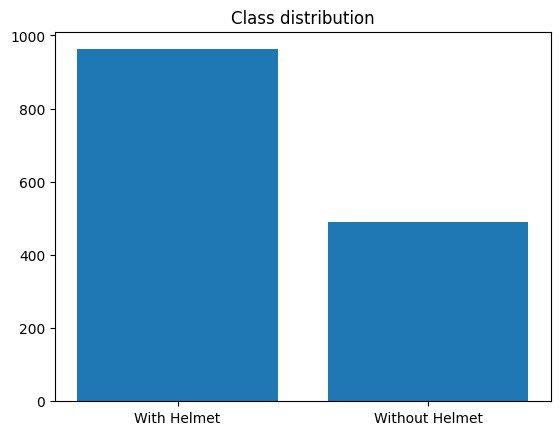

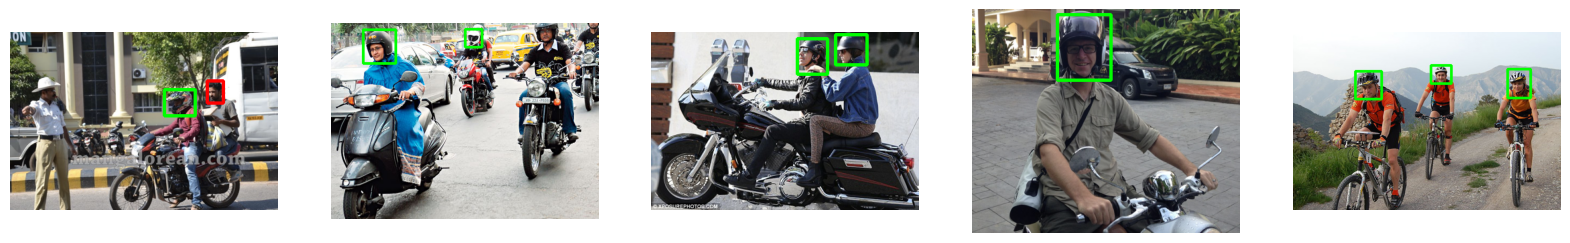

In [ ]:
import xml.etree.ElementTree as ET, cv2, random
import matplotlib.pyplot as plt
from collections import Counter

def parse_xml(path):
    objs = []
    for o in ET.parse(path).getroot().findall('object'):
        b = o.find('bndbox')
        objs.append((o.find('name').text.strip(), *[int(float(b.find(k).text)) for k in ('xmin', 'ymin', 'xmax', 'ymax')]))
    return objs

counts = Counter(o[0] for x in xml_files for o in parse_xml(x))
print(dict(counts))
plt.bar(counts.keys(), counts.values()); plt.title('Class distribution'); plt.show()

plt.figure(figsize=(20, 4))
for i, xp in enumerate(random.sample(xml_files, 5)):
    img = cv2.imread(os.path.join(IMG_DIR, os.path.basename(xp)[:-4] + '.png'))
    for n, x1, y1, x2, y2 in parse_xml(xp):
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0) if n == 'With Helmet' else (0, 0, 255), 3)
    plt.subplot(1, 5, i + 1); plt.imshow(img[..., ::-1]); plt.axis('off')
plt.show()

## Cell 4: Data cleaning checks

In [ ]:
stems_x = {os.path.basename(p)[:-4] for p in xml_files}
stems_i = {os.path.basename(p)[:-4] for p in img_files}
corrupt = empty = outside = 0
for xp in xml_files:
    img = cv2.imread(os.path.join(IMG_DIR, os.path.basename(xp)[:-4] + '.png'))
    if img is None:
        corrupt += 1
        continue
    h, w = img.shape[:2]
    objs = parse_xml(xp)
    empty += len(objs) == 0
    outside += any(x1 < 0 or y1 < 0 or x2 > w or y2 > h for _, x1, y1, x2, y2 in objs)
print('Missing pairs:', len(stems_x ^ stems_i), '| Corrupt:', corrupt, '| Empty:', empty, '| Images with boxes outside:', outside)

Missing pairs: 0 | Corrupt: 0 | Empty: 3 | Images with boxes outside: 15


## Cell 5: Pascal VOC to YOLO format

In [ ]:
CLASS_MAP = {'With Helmet': 0, 'Without Helmet': 1}
os.makedirs('/content/labels_all', exist_ok=True)
for xp in xml_files:
    stem = os.path.basename(xp)[:-4]
    h, w = cv2.imread(os.path.join(IMG_DIR, stem + '.png')).shape[:2]
    lines = []
    for n, x1, y1, x2, y2 in parse_xml(xp):
        x1, x2 = max(0, min(x1, w)), max(0, min(x2, w))
        y1, y2 = max(0, min(y1, h)), max(0, min(y2, h))
        if x2 > x1 and y2 > y1:
            lines.append(f"{CLASS_MAP[n]} {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}")
    open(f'/content/labels_all/{stem}.txt', 'w').write('\n'.join(lines))
print(len(os.listdir('/content/labels_all')), 'label files created')

764 label files created


## Cell 6: Train / Val / Test split (70 / 20 / 10)

In [ ]:
import shutil
OUT = '/content/helmet_yolo'
shutil.rmtree(OUT, ignore_errors=True)
stems = sorted(os.path.basename(p)[:-4] for p in img_files)
random.seed(42)
random.shuffle(stems)
a = int(0.7 * len(stems))
b = a + int(0.2 * len(stems))
for s, items in {'train': stems[:a], 'val': stems[a:b], 'test': stems[b:]}.items():
    os.makedirs(f'{OUT}/images/{s}')
    os.makedirs(f'{OUT}/labels/{s}')
    for st in items:
        shutil.copy(f'{IMG_DIR}/{st}.png', f'{OUT}/images/{s}/')
        shutil.copy(f'/content/labels_all/{st}.txt', f'{OUT}/labels/{s}/')
    print(s, len(items))

train 534
val 152
test 78


## Cell 7: data.yaml

In [ ]:
DATA_YAML = f'{OUT}/data.yaml'
open(DATA_YAML, 'w').write(f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 2\nnames:\n  0: With Helmet\n  1: Without Helmet\n")
print(open(DATA_YAML).read())

path: /content/helmet_yolo
train: images/train
val: images/val
test: images/test
nc: 2
names:
  0: With Helmet
  1: Without Helmet



## Cell 8: Training (YOLO26m)

In [ ]:
from ultralytics import YOLO

PROJECT_DIR = '/content/drive/MyDrive/helmet_runs'
RUN_NAME = 'yolo26m_helmet'

best_val_loss = float('inf')

def stop_on_loss_increase(trainer):
    global best_val_loss
    val_loss = sum(v for k, v in trainer.metrics.items()
                   if k.startswith('val/') and k.endswith('loss'))
    if val_loss > best_val_loss:
        trainer.stop = True
    else:
        best_val_loss = val_loss

model = YOLO('yolo26m.pt')
model.add_callback('on_fit_epoch_end', stop_on_loss_increase)

model.train(data=DATA_YAML, epochs=100, patience=30, imgsz=640, batch=16, seed=42, device=0,
            project=PROJECT_DIR, name=RUN_NAME, exist_ok=True,
            scale=0.9, cls=1.0, cos_lr=True, close_mosaic=15)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=1.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b4c683963f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

## Cell 9: Training curves

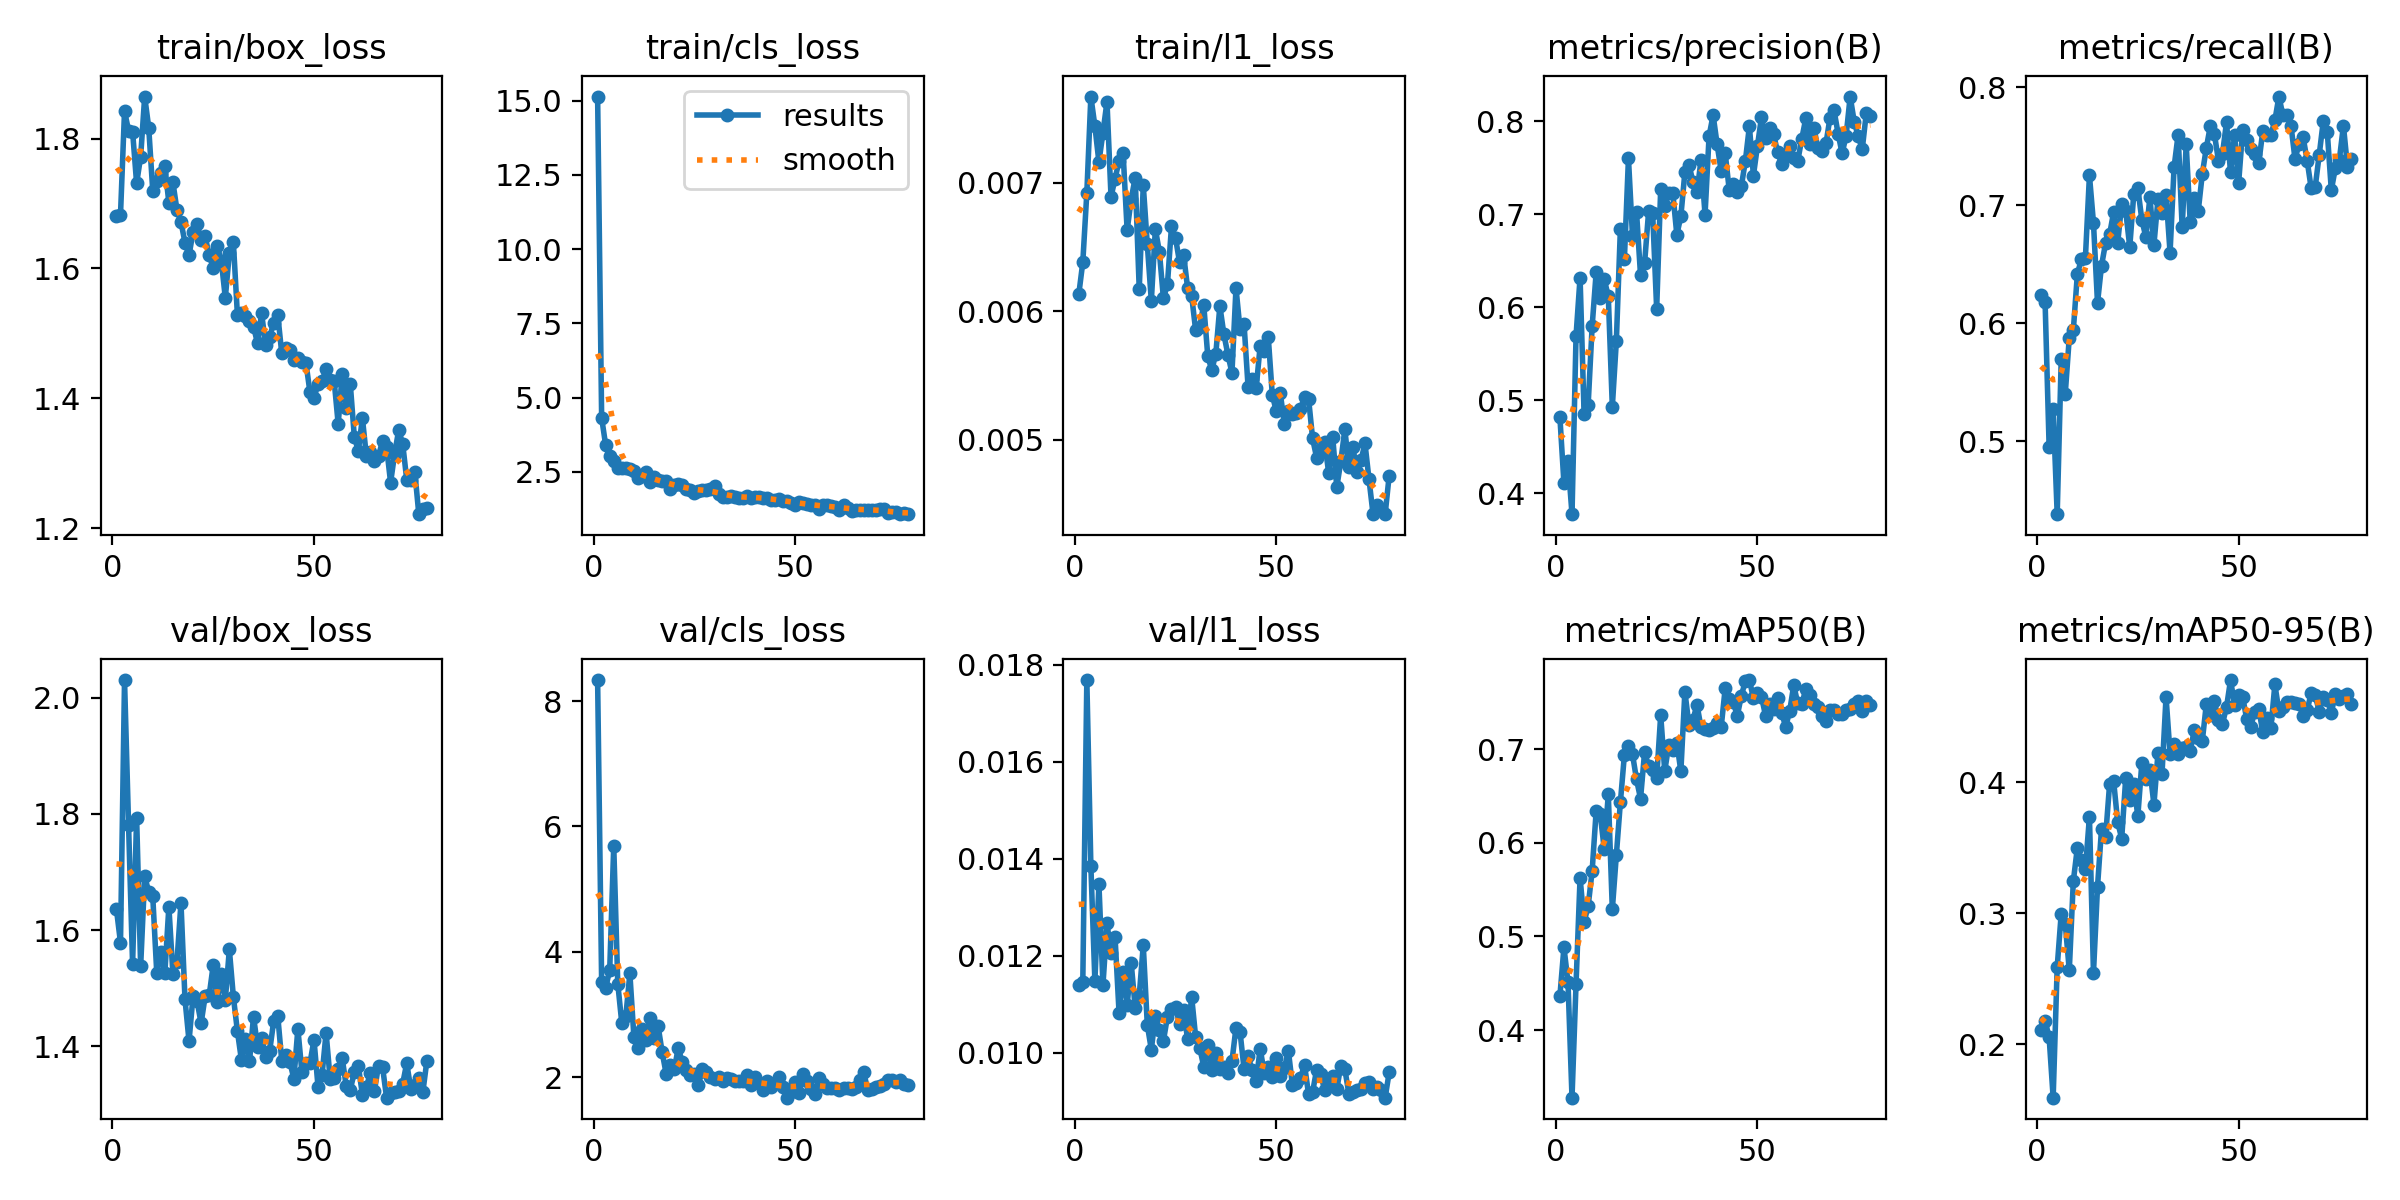

In [ ]:
import os
from IPython.display import Image, display

PROJECT_DIR = '/content/drive/MyDrive/helmet_runs'
RUN_NAME = 'yolo26m_helmet'
path = f'{PROJECT_DIR}/{RUN_NAME}/results.png'

if os.path.exists(path):
    display(Image(path))
    print('results.png loaded')
else:
    print('results.png not found:', path)
    print('Folders in helmet_runs:', os.listdir(PROJECT_DIR) if os.path.exists(PROJECT_DIR) else 'PROJECT_DIR not found')

## Cell 10: Test set evaluation

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 68.6±51.8 MB/s, size: 480.2 KB)
val: Scanning /content/helmet_yolo/labels/test... 78 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 78/78 213.9it/s 0.4s
val: New cache created: /content/helmet_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.4it/s 3.7s
                   all         78        162       0.75      0.761      0.812      0.466
           With Helmet         55        106      0.763      0.821      0.837      0.528
        Without Helmet         31         56      0.737      0.701      0.787      0.403
Speed: 3.7ms preprocess, 25.0ms inference, 0.0ms loss, 5.7ms postprocess per image
Results saved to /content/drive/MyDrive/helmet_runs/test_eval
P=0.750  R=0.761  mAP50

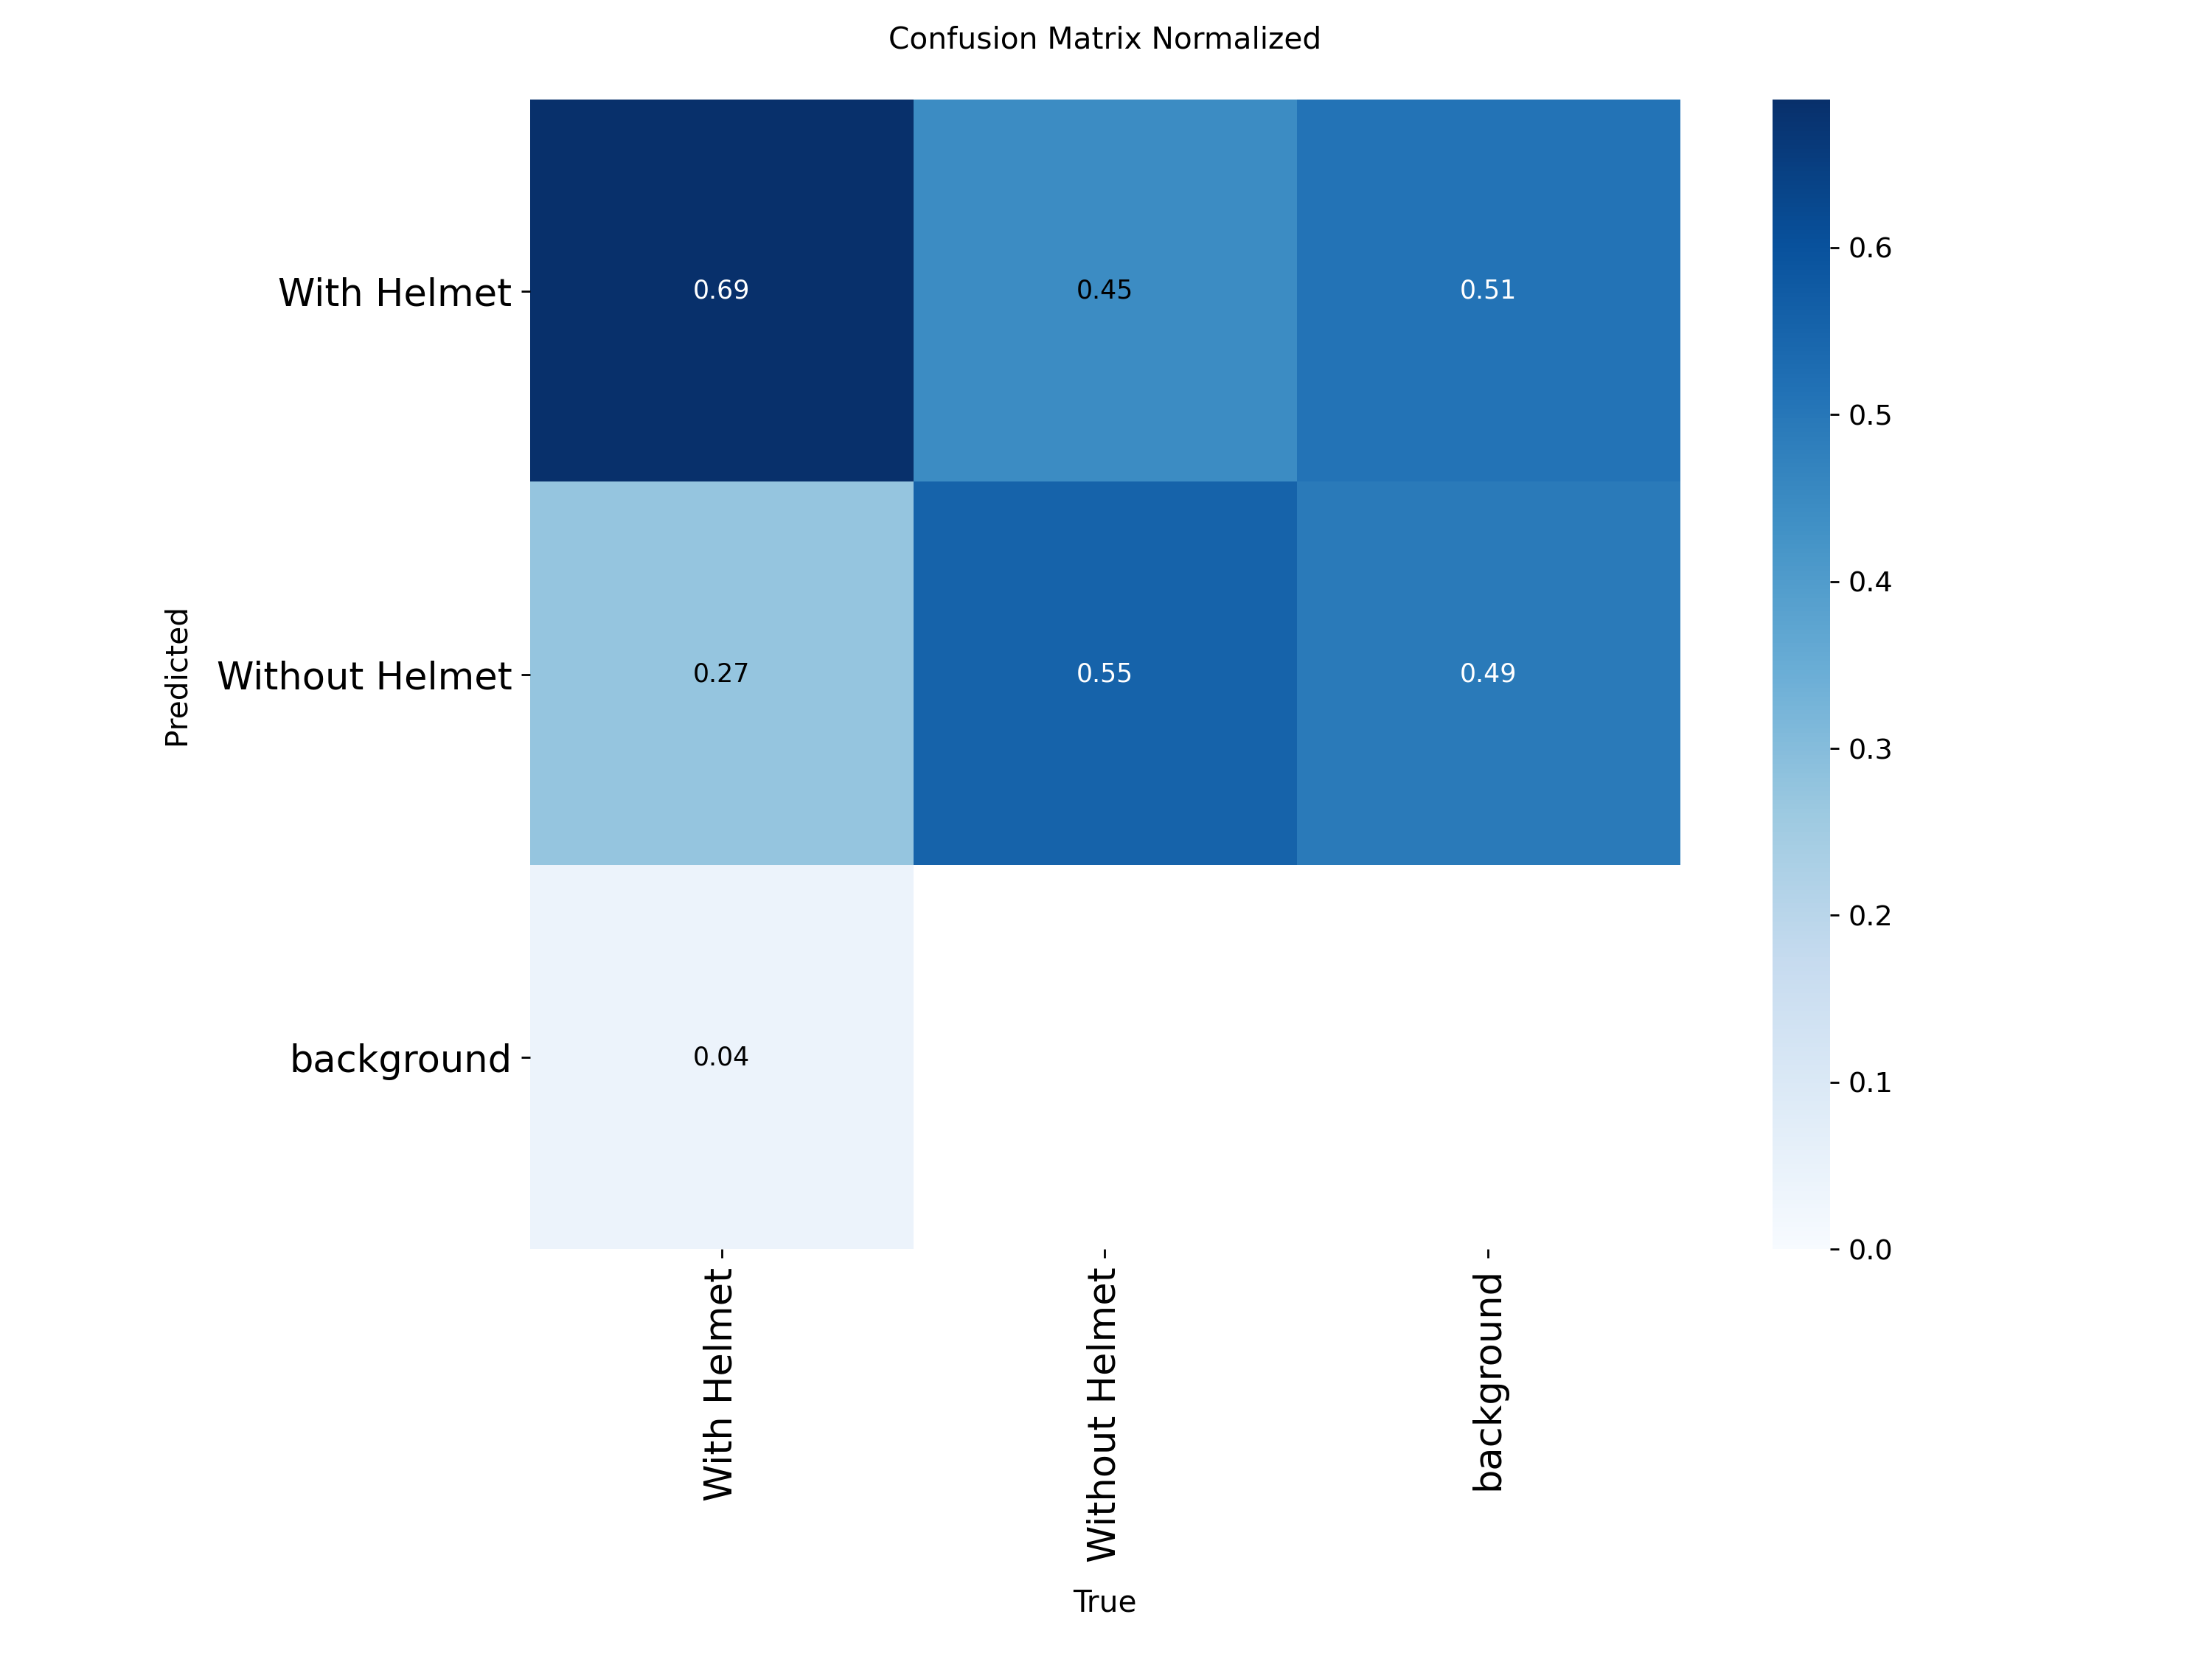

In [ ]:

PROJECT_DIR = '/content/drive/MyDrive/helmet_runs'
RUN_NAME = 'yolo26m_helmet'
DATA_YAML = '/content/helmet_yolo/data.yaml'
best_model = YOLO(f'{PROJECT_DIR}/{RUN_NAME}/weights/best.pt')
m = best_model.val(data=DATA_YAML, split='test', project=PROJECT_DIR, name='test_eval', exist_ok=True)
print(f"P={m.box.mp:.3f}  R={m.box.mr:.3f}  mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}")

for f in ['confusion_matrix_normalized.png', 'PR_curve.png']:
    img_path = f'{PROJECT_DIR}/test_eval/{f}'
    if os.path.exists(img_path):
        display(Image(img_path, width=600))
    else:
        print(f"Warning: {f} not found at {img_path}")

## Cell 11: Prediction on own image (Gradio)

In [ ]:
import gradio as gr

gr.Interface(lambda p: best_model.predict(p, conf=0.25, agnostic_nms=True)[0].plot()[..., ::-1],
             gr.Image(type="filepath"), gr.Image()).launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://debad51152e287200b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



image 1/1 /tmp/gradio/9369cc6d81c281224e6b8c1acb61fdfb9364469117a7d887c2fab65921f2d7dd/without helmet.jpg: 640x384 1 Without Helmet, 35.0ms
Speed: 1.5ms preprocess, 35.0ms inference, 6.5ms postprocess per image at shape (1, 3, 640, 384)

image 1/1 /tmp/gradio/e0a50b65256658abcecf56f08c0b858ca27f981ea203c358133e246932cee139/download.jpg: 352x640 1 Without Helmet, 60.0ms
Speed: 2.6ms preprocess, 60.0ms inference, 1.8ms postprocess per image at shape (1, 3, 352, 640)

image 1/1 /tmp/gradio/e42546742b43ebd0eead7b1c39e0c76d57cdb342510330750214ed1705bbcf7f/images (3).jpg: 384x640 4 With Helmets, 2 Without Helmets, 56.0ms
Speed: 2.8ms preprocess, 56.0ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)
